In [7]:
import pandas as pd
import matplotlib.pyplot as plt 

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [8]:
students = pd.DataFrame({
   "Hours_studied" : [1, 2, 3, 4, 5, 6, 7, 8, 9,],
   "Exam_scores" : [10, 15, 25, 30, 35, 40, 45, 50, 55,],
})
students

,Hours_studied,Exam_scores
0,1,10
1,2,15
2,3,25
3,4,30
4,5,35
5,6,40
6,7,45
7,8,50
8,9,55


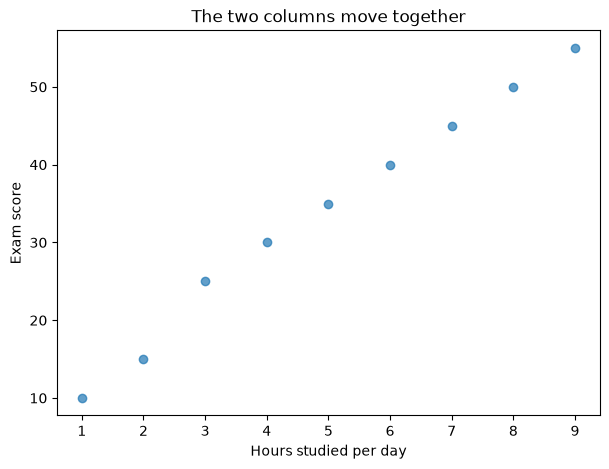

In [9]:
plt.figure(figsize=(7, 5))
plt.scatter(students["Hours_studied"], students["Exam_scores"], alpha=0.7)
plt.xlabel("Hours studied per day")
plt.ylabel("Exam score")
plt.title("The two columns move together")
plt.show()

In [10]:
scaler = StandardScaler()
students_scaled = scaler.fit_transform(students)

pca = PCA(n_components=1)

students_pca = pca.fit_transform(students_scaled)

print("Before:", students_scaled.shape)
print("After:", students_pca.shape)


Before: (9, 2)
After: (9, 1)


In [11]:
pd.DataFrame(students_pca, columns=["PC1"]).round(2)

,PC1
0,-2.26
1,-1.74
2,-0.98
3,-0.46
4,0.05
5,0.57
6,1.09
7,1.61
8,2.13


In [12]:
kept = pca.explained_variance_ratio_[0] * 100
print(f"PC1 keeps {kept:.1f}% of the information")

PC1 keeps 99.8% of the information


In [13]:
iris = load_iris(as_frame=True)
flowers = iris.data 
species = iris.target

flowers.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


In [15]:
flowers_scaled = StandardScaler().fit_transform(flowers)

pca = PCA(n_components=2)

flowers_pca = pca.fit_transform(students_scaled)

print("Before:", flowers_scaled.shape)
print("After:", flowers_pca.shape)

Before: (150, 4)
After: (9, 2)


In [16]:
flowers_2d = pd.DataFrame(flowers_pca, columns=["PC1", "PC2"])
flowers_2d["species"] = species.map({0: "setosa", 1: "versicolor", 2: "virginica"})
flowers_2d.head()

,PC1,PC2,species
0,-2.261446,0.070556,setosa
1,-1.743538,0.100371,setosa
2,-0.981583,-0.113862,setosa
3,-0.463675,-0.084047,setosa
4,0.054233,-0.054233,setosa
